# 🌱 Agriculture Data Analysis

### Project Overview

##### This project explores agricultural data to understand how factors such as crop type, farm area, irrigation methods, soil type, fertilizer and pesticide usage, and season relate to crop yield and water consumption.

##### The goal is to analyze agricultural patterns, identify key relationships between farming practices and productivity, and gain insights that can help support more efficient and sustainable farming.

### 1. Import Needed Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Cleaning Data

#### 2.1 Reviewing & Understanding Data

In [2]:
df=pd.read_csv('agriculture_dataset.csv')
df.head()

,Farm_ID,Crop_Type,Farm_Area(acres),Irrigation_Type,Fertilizer_Used(tons),Pesticide_Used(kg),Yield(tons),Soil_Type,Season,Water_Usage(cubic meters)
0,F001,Cotton,329.40,Sprinkler,8.14,2.21,14.44,Loamy,Kharif,76648.20
1,F002,Carrot,18.67,Manual,4.77,4.36,42.91,Peaty,Kharif,68725.54
2,F003,Sugarcane,306.03,Flood,2.91,0.56,33.44,Silty,Kharif,75538.56
3,F004,Tomato,380.21,Rain-fed,3.32,4.35,34.08,Silty,Zaid,45401.23
4,F005,Tomato,135.56,Sprinkler,8.33,4.48,43.28,Clay,Zaid,93718.69


In [6]:
df.columns

Index(['Farm_ID', 'Crop_Type', 'Farm_Area(acres)', 'Irrigation_Type',
       'Fertilizer_Used(tons)', 'Pesticide_Used(kg)', 'Yield(tons)',
       'Soil_Type', 'Season', 'Water_Usage(cubic meters)'],
      dtype='str')

In [5]:
df.shape

(50, 10)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Farm_ID                    50 non-null     str    
 1   Crop_Type                  50 non-null     str    
 2   Farm_Area(acres)           50 non-null     float64
 3   Irrigation_Type            50 non-null     str    
 4   Fertilizer_Used(tons)      50 non-null     float64
 5   Pesticide_Used(kg)         50 non-null     float64
 6   Yield(tons)                50 non-null     float64
 7   Soil_Type                  50 non-null     str    
 8   Season                     50 non-null     str    
 9   Water_Usage(cubic meters)  50 non-null     float64
dtypes: float64(5), str(5)
memory usage: 4.0 KB


In [8]:
df.describe()

,Farm_Area(acres),Fertilizer_Used(tons),Pesticide_Used(kg),Yield(tons),Water_Usage(cubic meters)
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,254.963800,4.905400,2.398000,27.059200,56724.295600
std,139.417782,2.732689,1.438613,13.345789,27264.992053
min,12.500000,0.500000,0.140000,3.860000,5869.750000
25%,135.710000,2.437500,0.972500,16.190000,37818.152500
50%,281.980000,5.045000,2.330000,28.970000,54097.075000
75%,368.107500,6.885000,3.417500,37.860000,82240.032500
max,483.880000,9.960000,4.990000,48.020000,94754.730000


In [11]:
df.describe(include='object')

C:\Users\SA\AppData\Local\Temp\ipykernel_2824\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Farm_ID,Crop_Type,Irrigation_Type,Soil_Type,Season
count,50,50,50,50,50
unique,50,10,5,5,3
top,F001,Cotton,Drip,Clay,Zaid
freq,1,7,15,14,23


#### 2.2 Check missing values & duplicates

In [12]:
# Missing values
df.isnull().sum()

Farm_ID                      0
Crop_Type                    0
Farm_Area(acres)             0
Irrigation_Type              0
Fertilizer_Used(tons)        0
Pesticide_Used(kg)           0
Yield(tons)                  0
Soil_Type                    0
Season                       0
Water_Usage(cubic meters)    0
dtype: int64

In [14]:
#Duplicated Values
df.duplicated().sum()

np.int64(0)

#### 2.3 Handle Outliers

In [15]:
for col in df.select_dtypes(include=['number']).columns:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    IQR=q3-q1
    LB=q1-1.5*IQR
    UB=q3+1.5*IQR
    df[col]=df[col].clip(lower=LB,upper=UB)
    outliers=df[(df[col]<LB)|(df[col]>UB)]

In [16]:
outliers

,Farm_ID,Crop_Type,Farm_Area(acres),Irrigation_Type,Fertilizer_Used(tons),Pesticide_Used(kg),Yield(tons),Soil_Type,Season,Water_Usage(cubic meters)


### 3. EDA(Exploratory Data Analysis)

#### 3.1 Crop Type Distribution

C:\Users\SA\AppData\Local\Temp\ipykernel_2824\3026084671.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  x = sns.countplot(data=df,x='Crop_Type',order=df['Crop_Type'].value_counts().index,palette='deep')


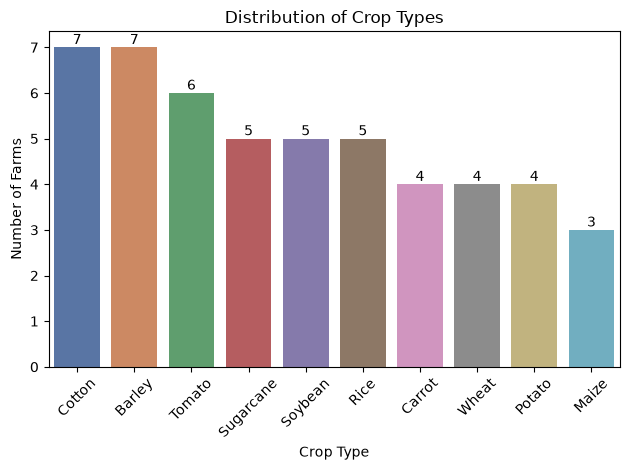

In [21]:
x = sns.countplot(data=df,x='Crop_Type',order=df['Crop_Type'].value_counts().index,palette='deep')
plt.title('Distribution of Crop Types')
plt.xlabel('Crop Type')
plt.ylabel('Number of Farms')
plt.xticks(rotation=45)
for i in x.containers:
    plt.bar_label(i)
plt.tight_layout()
plt.show()


#### 3.2 Distribution of Water Usage

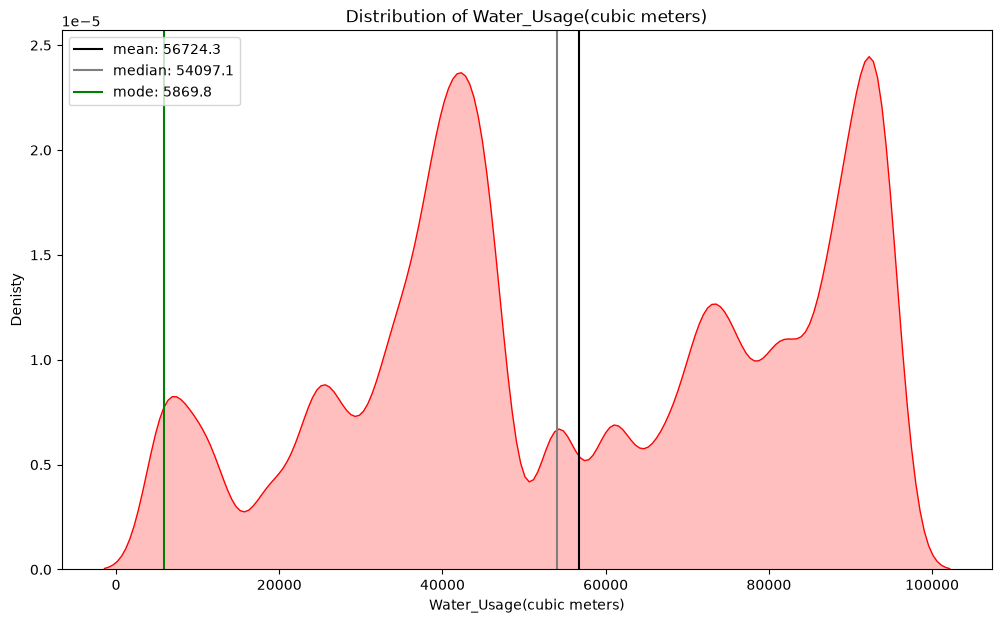

In [26]:
plt.figure(figsize=(12,7))
sns.kdeplot(x=df['Water_Usage(cubic meters)'],color='red',fill=True,bw_adjust=0.3,bw_method=0.3)
mean=df['Water_Usage(cubic meters)'].mean()
plt.axvline(mean,color='black',label=f'mean: {mean:.1f}')
median=df['Water_Usage(cubic meters)'].median()
plt.axvline(median,color='gray',label=f'median: {median:.1f}')
mode=df['Water_Usage(cubic meters)'].mode()[0]
plt.axvline(mode,color='green',label=f'mode: {mode:.1f}')
plt.legend()
plt.xlabel('Water_Usage(cubic meters)')
plt.ylabel('Denisty')
plt.title('Distribution of Water_Usage(cubic meters)')
plt.show()

#### 3.3 Distribution of Irrigation Types

C:\Users\SA\AppData\Local\Temp\ipykernel_2824\2571477245.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  x = sns.countplot(data=df,x='Irrigation_Type',order=df['Irrigation_Type'].value_counts().index,palette='deep')


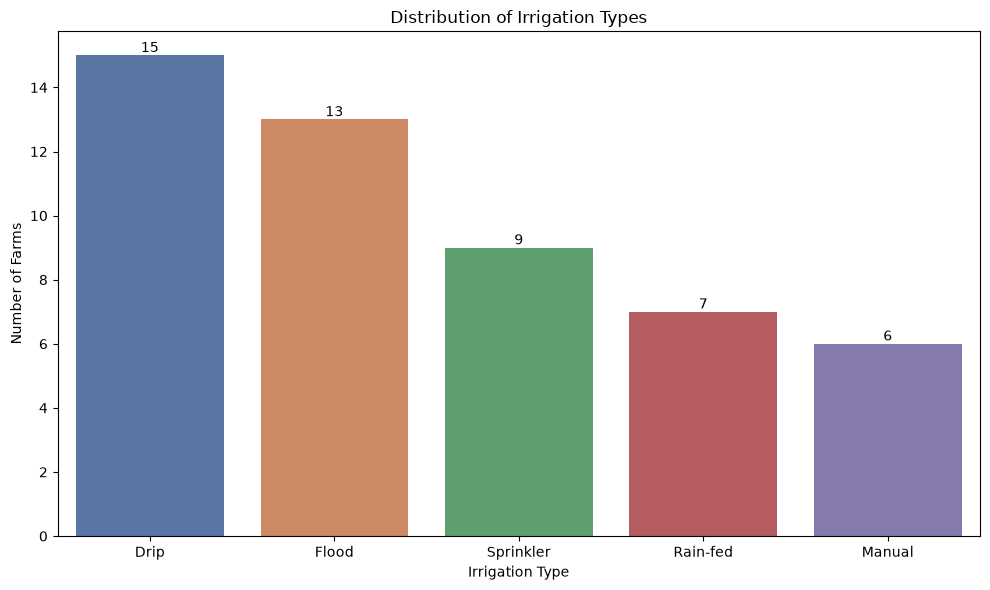

In [31]:
plt.figure(figsize=(10, 6))
x = sns.countplot(data=df,x='Irrigation_Type',order=df['Irrigation_Type'].value_counts().index,palette='deep')
plt.title('Distribution of Irrigation Types')
plt.xlabel('Irrigation Type')
plt.ylabel('Number of Farms')
for i in x.containers:
    plt.bar_label(i)
plt.tight_layout()
plt.show()

#### 3.4 Distribution of Soil Types

C:\Users\SA\AppData\Local\Temp\ipykernel_2824\109262610.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  x= sns.countplot(data=df,x='Soil_Type',order=df['Soil_Type'].value_counts().index,palette='deep')


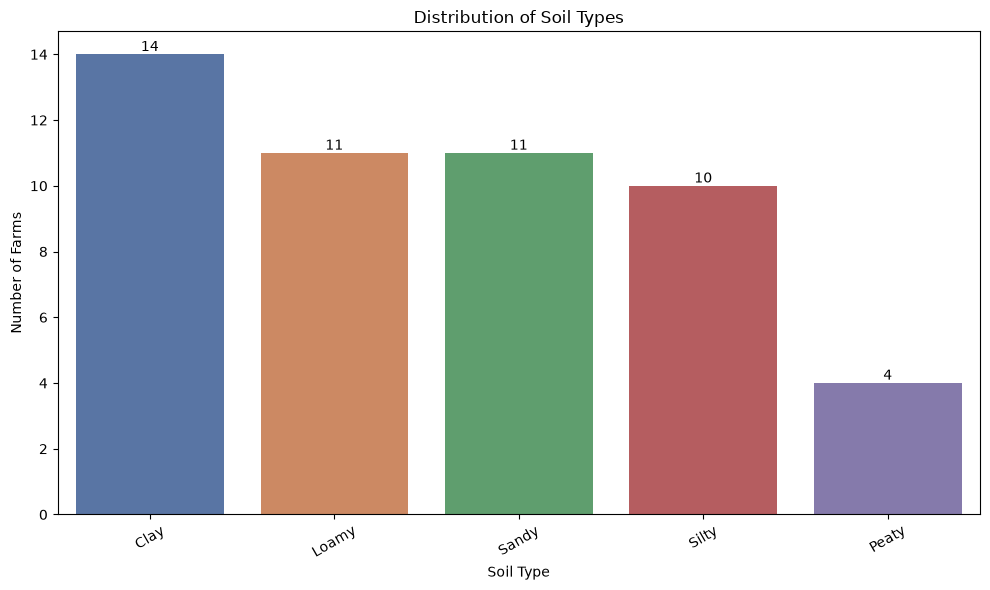

In [32]:
plt.figure(figsize=(10, 6))
x= sns.countplot(data=df,x='Soil_Type',order=df['Soil_Type'].value_counts().index,palette='deep')
plt.title('Distribution of Soil Types')
plt.xlabel('Soil Type')
plt.ylabel('Number of Farms')
for i in x.containers:
    plt.bar_label(i)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### 3.5 Distribution of Agricultural Seasons

C:\Users\SA\AppData\Local\Temp\ipykernel_2824\587029487.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  x = sns.countplot(data=df,x='Season',order=df['Season'].value_counts().index,palette='deep')


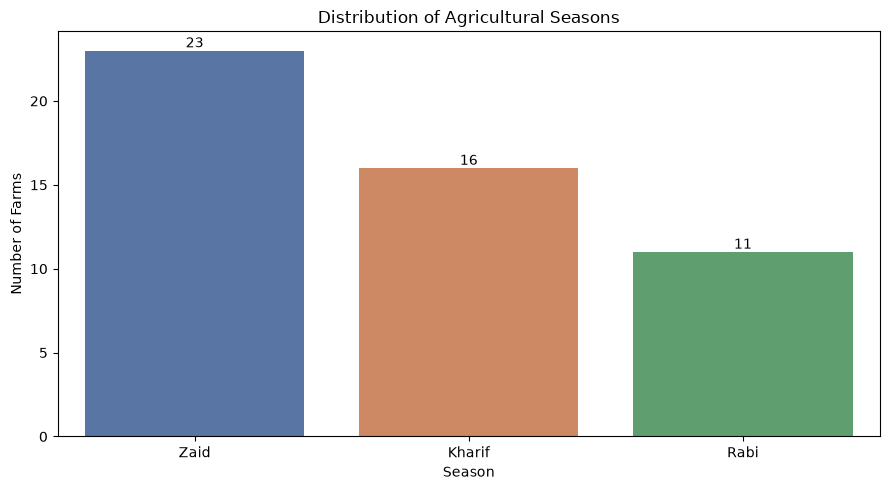

In [35]:
plt.figure(figsize=(9, 5))
x = sns.countplot(data=df,x='Season',order=df['Season'].value_counts().index,palette='deep')
plt.title('Distribution of Agricultural Seasons')
plt.xlabel('Season')
plt.ylabel('Number of Farms')
for i in x.containers:
    plt.bar_label(i)
plt.tight_layout()
plt.show()

#### 3.6 Farm Area vs. Crop Yield

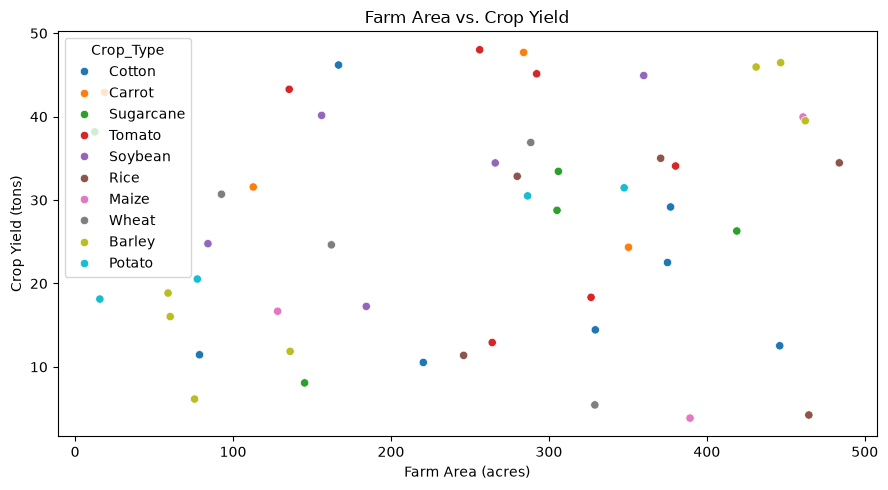

In [23]:
#هل مساحة المزرعة مرتبطة بكمية الإنتاج؟
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df,x='Farm_Area(acres)',y='Yield(tons)',hue='Crop_Type')
plt.title('Farm Area vs. Crop Yield')
plt.xlabel('Farm Area (acres)')
plt.ylabel('Crop Yield (tons)')
plt.tight_layout()
plt.show()


#### 3.7 Crop Yield by Irrigation Type

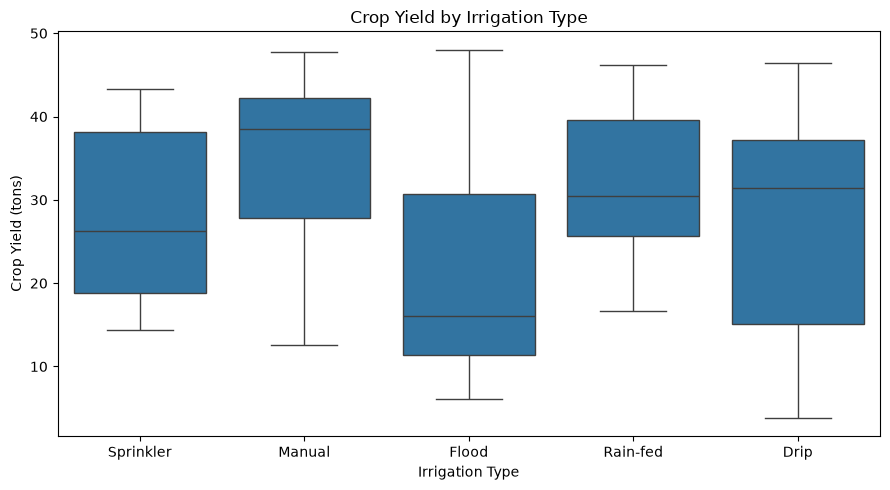

In [24]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df,x='Irrigation_Type',y='Yield(tons)')
plt.title('Crop Yield by Irrigation Type')
plt.xlabel('Irrigation Type')
plt.ylabel('Crop Yield (tons)')
plt.tight_layout()
plt.show()

#### 3.8 Crop Yield by Crop Type

C:\Users\SA\AppData\Local\Temp\ipykernel_2824\3515348063.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  x=sns.barplot(data=df,x='Crop_Type',y='Yield(tons)',estimator='mean',errorbar=None,order=df.groupby('Crop_Type')['Yield(tons)'].mean().sort_values(ascending=False).index,palette='deep')


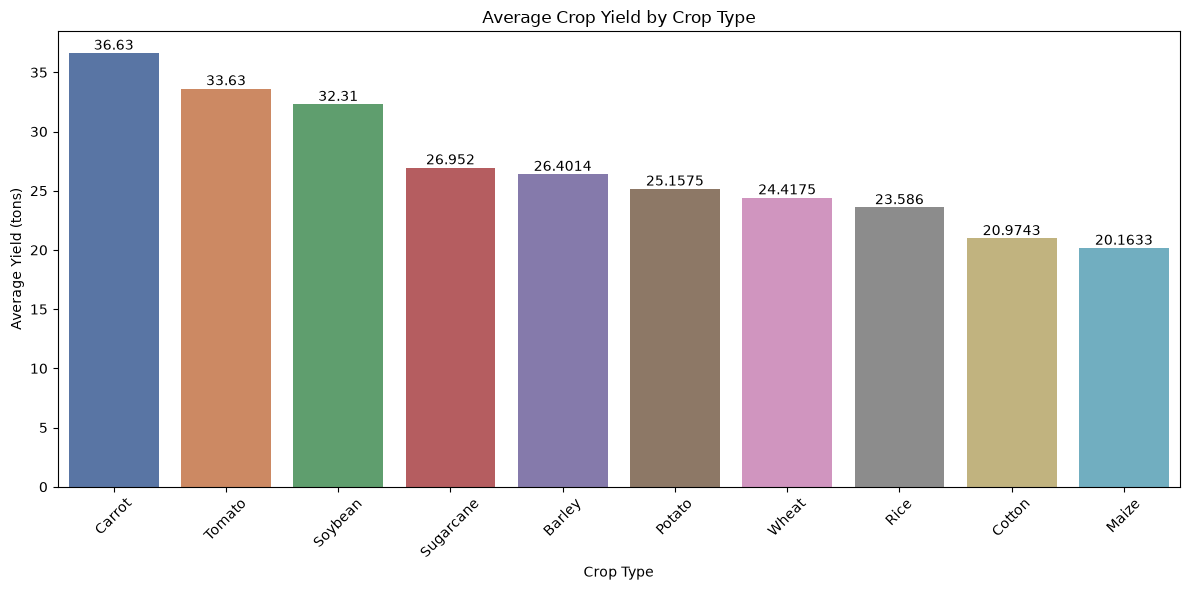

In [37]:
plt.figure(figsize=(12, 6))
x=sns.barplot(data=df,x='Crop_Type',y='Yield(tons)',estimator='mean',errorbar=None,order=df.groupby('Crop_Type')['Yield(tons)'].mean().sort_values(ascending=False).index,palette='deep')
plt.title('Average Crop Yield by Crop Type')
plt.xlabel('Crop Type')
plt.ylabel('Average Yield (tons)')
plt.xticks(rotation=45)
for i in x.containers:
    plt.bar_label(i)
plt.tight_layout()
plt.show()

#### 3.9 Water Use Efficiency by Crop Type

In [38]:
water_efficiency = (df.groupby('Crop_Type').apply(lambda x: x['Yield(tons)'].sum()/x['Water_Usage(cubic meters)'].sum() * 1000,include_groups=False).sort_values(ascending=False).reset_index(name='Yield_per_1000_m3'))

C:\Users\SA\AppData\Local\Temp\ipykernel_2824\2236474798.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  x=sns.barplot(data=water_efficiency,x='Crop_Type',y='Yield_per_1000_m3',order=water_efficiency['Crop_Type'],palette='deep')


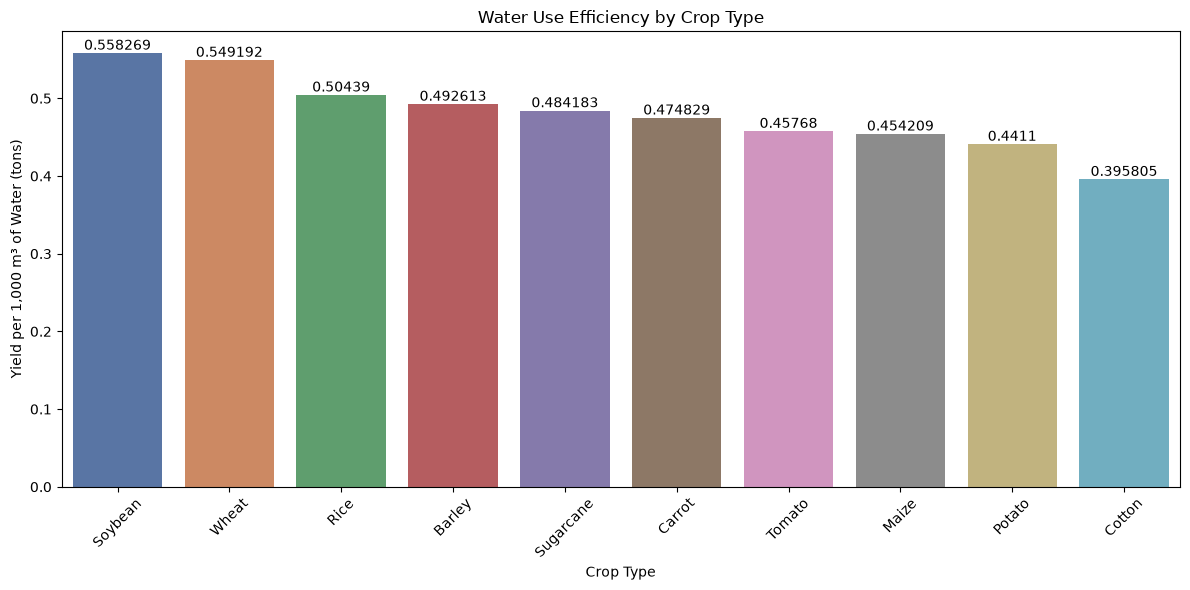

In [40]:
plt.figure(figsize=(12, 6))
x=sns.barplot(data=water_efficiency,x='Crop_Type',y='Yield_per_1000_m3',order=water_efficiency['Crop_Type'],palette='deep')
plt.title('Water Use Efficiency by Crop Type')
plt.xlabel('Crop Type')
plt.ylabel('Yield per 1,000 m³ of Water (tons)')
plt.xticks(rotation=45)
for i in x.containers:
    plt.bar_label(i)
plt.tight_layout()
plt.show()

#### 3.10 Water Usage vs Crop Yield

In [42]:
df.head(2)

,Farm_ID,Crop_Type,Farm_Area(acres),Irrigation_Type,Fertilizer_Used(tons),Pesticide_Used(kg),Yield(tons),Soil_Type,Season,Water_Usage(cubic meters)
0,F001,Cotton,329.40,Sprinkler,8.14,2.21,14.44,Loamy,Kharif,76648.20
1,F002,Carrot,18.67,Manual,4.77,4.36,42.91,Peaty,Kharif,68725.54


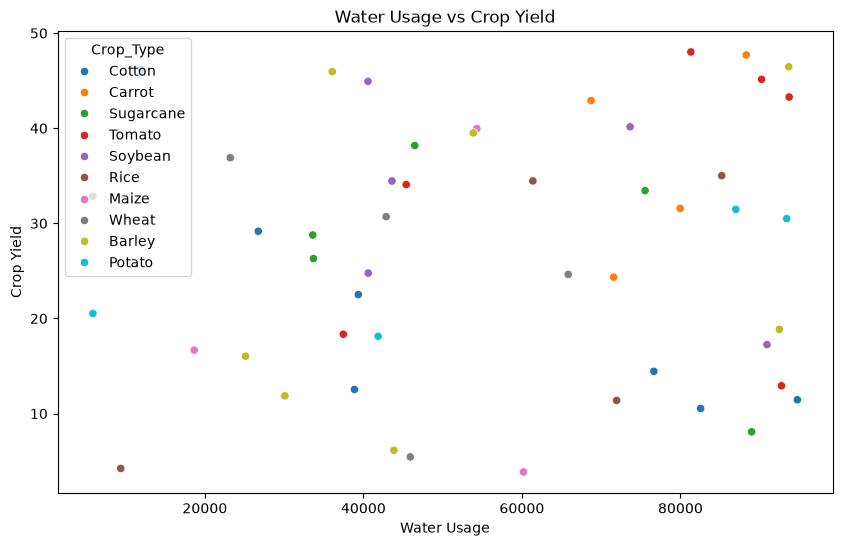

In [43]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x='Water_Usage(cubic meters)',y='Yield(tons)',hue='Crop_Type')
plt.title('Water Usage vs Crop Yield')
plt.xlabel('Water Usage')
plt.ylabel('Crop Yield')
plt.show()

#### 3.11 Fertilizer Usage vs Crop Yield

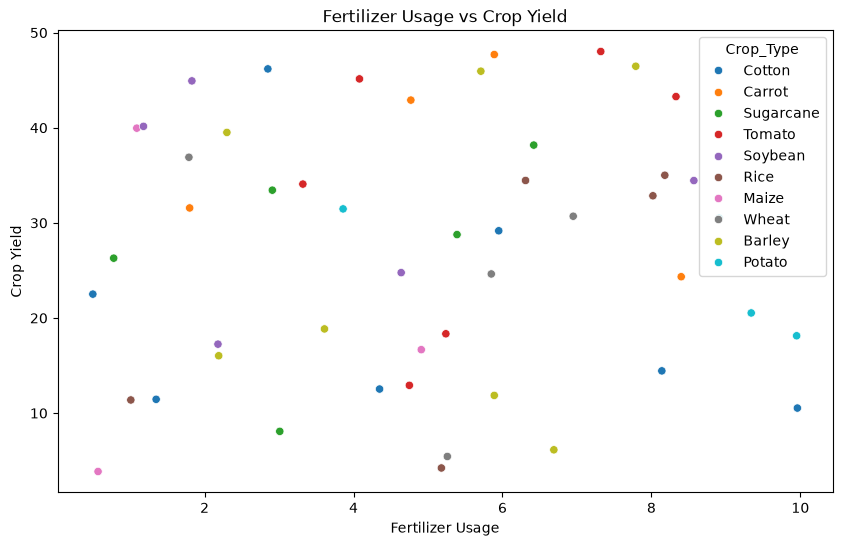

In [45]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x='Fertilizer_Used(tons)',y='Yield(tons)',hue='Crop_Type')
plt.title('Fertilizer Usage vs Crop Yield')
plt.xlabel('Fertilizer Usage')
plt.ylabel('Crop Yield')
plt.show()

#### 3.12 Correlation Heatmap

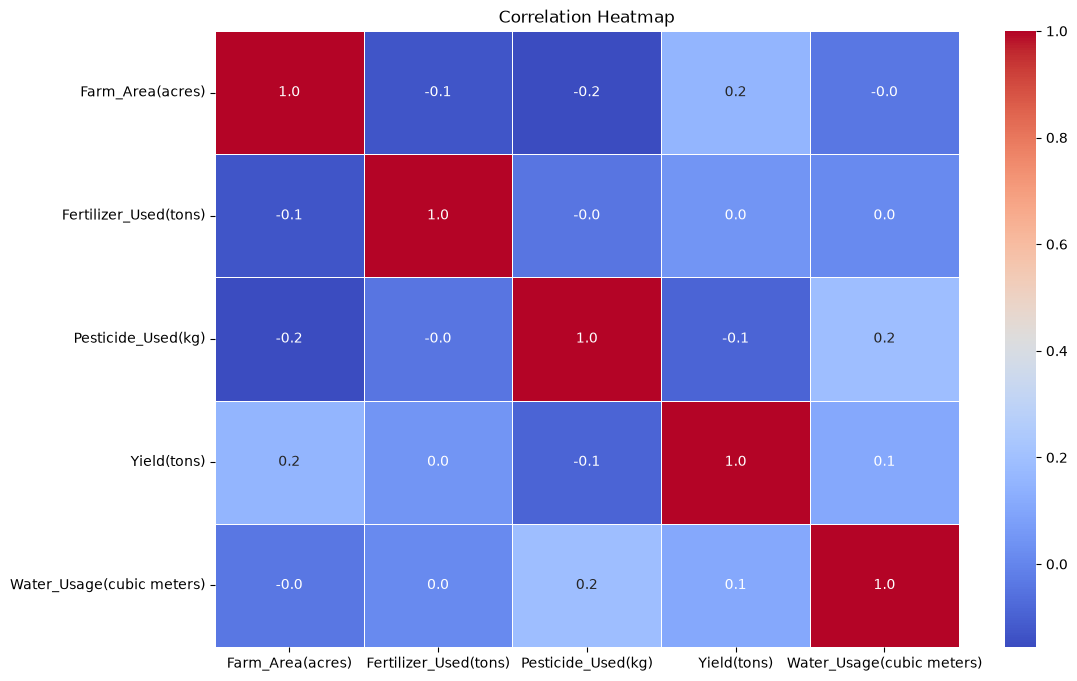

In [46]:
plt.figure(figsize=(12, 8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.1f',linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

## Conclusion & Key Insights

This analysis explored agricultural data from 50 farms to understand crop production, resource usage, and agricultural patterns.

Key findings include:

- **Crop Performance:** Carrot achieved the highest average crop yield, while Maize recorded the lowest.
- **Water Efficiency:** Soybean showed the highest water use efficiency, followed by Wheat and Rice.
- **Irrigation Methods:** Drip irrigation was the most widely used method, while Manual irrigation showed the highest median yield in the dataset.
- **Agricultural Patterns:** Cotton and Barley were the most frequently represented crops, Clay was the most common soil type, and Zaid was the most frequent agricultural season.
- **Correlation Analysis:** Farm area, water usage, fertilizer usage, and pesticide usage showed weak linear correlations with crop yield.

Overall, the analysis highlights differences in crop productivity and water use efficiency across crop types. However, the dataset is relatively small, and the observed relationships do not establish causation. Further analysis using larger datasets and additional agricultural factors could provide deeper insights into crop productivity and resource management.